# Credit Card Fraud Detection — Interview-Ready End-to-End Workflow

This notebook builds a leakage-aware fraud-detection workflow around the Kaggle
`creditcard.csv` columns (`Time`, `V1`–`V28`, `Amount`, `Class`). It is written
to explain the reasoning behind each choice, not just produce a score.

**Target:** `Class` (`1` = fraud, `0` = genuine). The canonical dataset has about
0.17% fraud. The default file path is `./creditcard.csv`; edit `DATA_PATH` if
your file is elsewhere. Run cells from top to bottom. Cross-validation and
randomized/nested searches can take a long time, especially on CPU.

**Reproducibility:** fixed seed 42 throughout except the explicitly different
outer nested-CV shuffle seed. **The holdout is reserved:** no model selection
or threshold choice uses it; the final evaluation cell is the only cell that
computes holdout metrics.

## 0. Environment and imports

**What / why:** Import the tools for tabular analysis, leakage-safe pipelines,
metrics, and persistence. We use `imblearn.pipeline.Pipeline`, rather than the
ordinary sklearn pipeline, because samplers must run only while fitting each
training fold. **Why not install everything automatically?** Silent installs
can change environments unexpectedly; install missing packages explicitly.
XGBoost is optional and will be clearly skipped if it is unavailable.

In [1]:
# If needed, install in your environment first:
# %pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn scipy joblib xgboost

from pathlib import Path
import re
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import loguniform, randint, uniform
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.model_selection import (
    RandomizedSearchCV, StratifiedKFold, cross_validate, cross_val_predict,
    train_test_split,
)
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
    PrecisionRecallDisplay, RocCurveDisplay, make_scorer,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42
DATA_PATH = Path("./creditcard.csv")
TARGET = "Class"
TEST_SIZE = 0.20

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
    warnings.warn(
        "XGBoost is not installed; its model will be skipped. Install with "
        "`python -m pip install xgboost` and rerun to include it.",
        ImportWarning,
    )

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}. Set DATA_PATH to your creditcard.csv."
    )

print(f"Reading {DATA_PATH.resolve()}")

Reading D:\projects\credit_card_fraud_detection\Credit_card_fraud_detection\creditcard.csv


## 1. Exploratory data analysis (EDA)

**What:** Inspect the table shape, dtypes, missingness, exact duplicate rows,
class counts/percentages, transaction-time and amount distributions, and
correlations. **Why:** These checks reveal data quality issues, the degree of
imbalance, and potentially useful feature structure before modeling.
**Why not accuracy?** A classifier that predicts “genuine” for every row scores
about 99.83% accuracy on the canonical data while detecting zero fraud. We
therefore prioritize precision-recall area (average precision), which focuses
on the rare positive class. EDA is descriptive; no transformations are fitted
here and no holdout score is computed.

Shape: (284807, 31)


,dtype
Time,float64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


,missing_count
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Exact duplicate rows: 1081


,count,percent
Class,,
0,284315,99.8273
1,492,0.1727


Always-genuine accuracy baseline: 99.8273%; fraud recall: 0%.


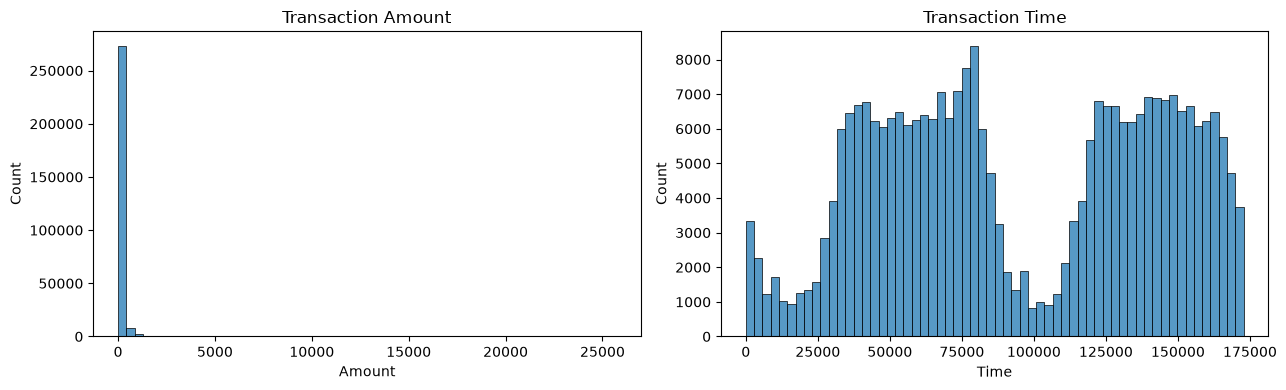

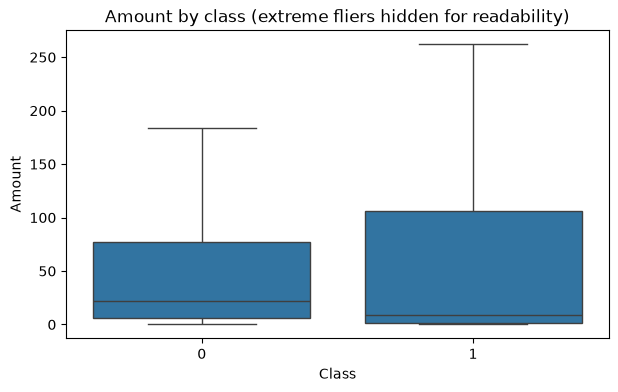

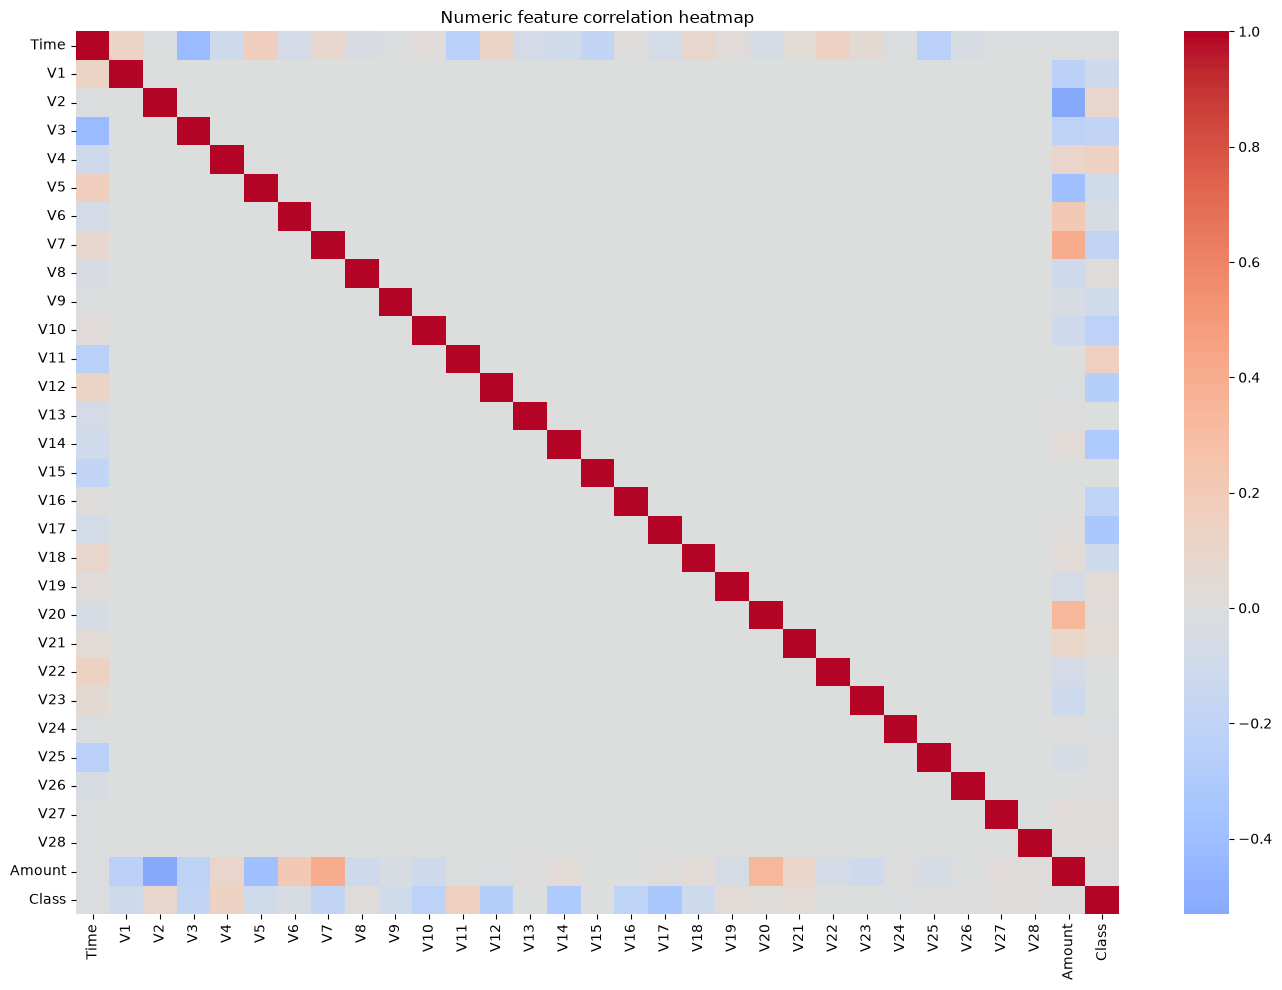

In [2]:
df = pd.read_csv(DATA_PATH)
if TARGET not in df.columns:
    raise ValueError(f"Expected target column {TARGET!r}; found {df.columns.tolist()}")
if not set(pd.Series(df[TARGET].dropna().unique())).issubset({0, 1}):
    raise ValueError("Class must contain binary labels 0 and 1.")

print("Shape:", df.shape)
display(df.dtypes.rename("dtype").to_frame())
display(df.isna().sum().rename("missing_count").to_frame())
print("Exact duplicate rows:", int(df.duplicated().sum()))

class_counts = df[TARGET].value_counts(dropna=False).sort_index()
class_summary = pd.DataFrame({
    "count": class_counts,
    "percent": (class_counts / len(df) * 100).round(4),
})
display(class_summary)
fraud_rate = float((df[TARGET] == 1).mean())
print(f"Always-genuine accuracy baseline: {1 - fraud_rate:.4%}; fraud recall: 0%.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
if "Amount" in df:
    sns.histplot(df["Amount"], bins=60, ax=axes[0])
    axes[0].set_title("Transaction Amount")
else:
    axes[0].text(0.5, 0.5, "Amount column not present", ha="center")
if "Time" in df:
    sns.histplot(df["Time"], bins=60, ax=axes[1])
    axes[1].set_title("Transaction Time")
else:
    axes[1].text(0.5, 0.5, "Time column not present", ha="center")
plt.tight_layout()
plt.show()

if "Amount" in df:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=TARGET, y="Amount", showfliers=False)
    plt.title("Amount by class (extreme fliers hidden for readability)")
    plt.show()

numeric_eda = df.select_dtypes(include=np.number)
plt.figure(figsize=(14, 10))
sns.heatmap(numeric_eda.corr(), cmap="coolwarm", center=0, cbar=True)
plt.title("Numeric feature correlation heatmap")
plt.tight_layout()
plt.show()

## 2. Split before preprocessing

**What:** Reserve the last 20% of transactions in time order when `Time` exists;
otherwise use a stratified random 80/20 split. **Why:** A chronological split
better resembles deployment on future transactions and prevents training on
later observations. `Time` in this dataset is elapsed seconds from an unknown
origin, not a calendar timestamp. Stratification is preferable when no
meaningful order exists because it preserves rare-class proportions.
**Why not preprocess before splitting?** Imputation, scaling, encoding, feature
selection, and resampling fitted using the full dataset leak information from
validation/test rows. All such fitting happens inside the training pipelines.

In [3]:
if "Time" in df.columns:
    ordered = df.sort_values("Time", kind="mergesort").reset_index(drop=True)
    split_at = int(len(ordered) * (1 - TEST_SIZE))
    train_raw, test_raw = ordered.iloc[:split_at].copy(), ordered.iloc[split_at:].copy()
    split_description = "chronological 80/20 split by Time"
else:
    train_raw, test_raw = train_test_split(
        df, test_size=TEST_SIZE, stratify=df[TARGET], random_state=RANDOM_STATE
    )
    train_raw, test_raw = train_raw.copy(), test_raw.copy()
    split_description = "stratified random 80/20 split"

X_train_raw = train_raw.drop(columns=[TARGET])
y_train_raw = train_raw[TARGET].astype(int).copy()
X_test_raw = test_raw.drop(columns=[TARGET])
y_test = test_raw[TARGET].astype(int).copy()
print(split_description)
print("Training rows:", len(X_train_raw), "| holdout reserved:", len(X_test_raw))
if y_train_raw.nunique() != 2:
    raise ValueError("Training data must contain both classes for stratified CV.")

chronological 80/20 split by Time
Training rows: 227845 | holdout reserved: 56962


## 3. Fold-fitted preprocessing

**What:** Remove exact duplicate training examples (never use holdout rows to
clean the training set), drop obvious identifier columns, create `log1p(Amount)`,
then use a `ColumnTransformer`. Numeric columns receive median imputation and
`RobustScaler`; low-cardinality categoricals get one-hot encoding and
high-cardinality categoricals get fold-fitted frequency encoding.

**Why RobustScaler?** It scales using medians and interquartile ranges, so a few
extreme transaction amounts distort it less than mean/standard-deviation
`StandardScaler`. **Why not label encode nominal features?** Integer codes
invent an ordering. One-hot is safe for low-cardinality categories; frequency
encoding maps categories to their training-fold frequency and controls width
for high-cardinality data. Target encoding can be useful but requires careful
out-of-fold smoothing to avoid label leakage. Unknown one-hot categories are
ignored; unknown frequency categories map to zero.

Scaling matters for LR, SVM, and KNN because their optimization or distances
depend on feature scale. Decision trees, random forests, and XGBoost generally
do not require scaling, though the shared transformer keeps the comparison
consistent.

In [4]:
def obvious_id_columns(columns):
    # Time is an ordering feature, not an identifier.
    pattern = re.compile(r"(^id$|_id$|^id_|transactionid|customerid)", re.IGNORECASE)
    return [c for c in columns if pattern.search(str(c)) and str(c).lower() != "time"]


# Deduplicate only within the training partition and keep feature/label alignment.
train_with_target = X_train_raw.copy()
train_with_target["__target__"] = y_train_raw.to_numpy()
train_with_target = train_with_target.drop_duplicates()
y_train = train_with_target.pop("__target__").astype(int)
X_train = train_with_target

id_columns = obvious_id_columns(X_train.columns)
X_train = X_train.drop(columns=id_columns)
print("Training duplicate rows removed:", len(X_train_raw) - len(X_train))
print("Dropped identifier columns:", id_columns or "none detected")


class AddLogAmount(BaseEstimator, TransformerMixin):
    # Add log1p of nonnegative Amount while preserving DataFrame columns.
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        if "Amount" in X.columns:
            X["Amount_log1p"] = np.log1p(X["Amount"].clip(lower=0))
        return X

    def get_feature_names_out(self, input_features=None):
        names = list(input_features) if input_features is not None else []
        if "Amount" in names and "Amount_log1p" not in names:
            names.append("Amount_log1p")
        return np.asarray(names, dtype=object)


class FrequencyEncoder(BaseEstimator, TransformerMixin):
    # Category frequencies are learned independently in each fit fold.
    def fit(self, X, y=None):
        frame = pd.DataFrame(X).astype("string").fillna("__MISSING__")
        self.frequency_maps_ = {
            col: frame[col].value_counts(normalize=True).to_dict()
            for col in frame.columns
        }
        self.n_features_in_ = frame.shape[1]
        self.feature_names_in_ = np.asarray(frame.columns, dtype=object)
        return self

    def transform(self, X):
        frame = pd.DataFrame(X).copy()
        frame.columns = self.feature_names_in_
        for col in frame.columns:
            values = frame[col].astype("string").fillna("__MISSING__")
            frame[col] = values.map(self.frequency_maps_[col]).fillna(0.0).astype(float)
        return frame.to_numpy()

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.feature_names_in_, dtype=object)


X_train_features = AddLogAmount().fit_transform(X_train)
numeric_columns = X_train_features.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_train_features.select_dtypes(exclude=np.number).columns.tolist()
low_cardinality = [c for c in categorical_columns if X_train_features[c].nunique(dropna=False) <= 20]
high_cardinality = [c for c in categorical_columns if c not in low_cardinality]

numeric_pipe = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
])
low_cardinality_pipe = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
high_cardinality_pipe = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
    ("frequency", FrequencyEncoder()),
])
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipe, numeric_columns),
        ("categorical_low", low_cardinality_pipe, low_cardinality),
        ("categorical_high", high_cardinality_pipe, high_cardinality),
    ],
    remainder="drop",
)
print("Numeric:", len(numeric_columns), "| low-cardinality:", low_cardinality,
      "| high-cardinality:", high_cardinality)

Training duplicate rows removed: 840
Dropped identifier columns: none detected
Numeric: 31 | low-cardinality: [] | high-cardinality: []


## 4. Imbalance strategy and training-only subsamples

**What:** Use class weights for LR, decision tree, random forest, and SVM;
XGBoost receives `scale_pos_weight = negatives / positives`; KNN uses
`RandomUnderSampler` inside its imbalanced-learn pipeline. The sampler is
therefore applied only when a training fold calls `fit`, never to validation
or holdout observations.

**Why not resample the whole dataset first?** It leaks duplicated/synthetic
information across folds and changes validation prevalence. For strong models,
class weights plus a training-only decision threshold are often simpler and
preserve all training observations. SMOTE is a valid alternative for some
datasets, but can create unrealistic synthetic points in sparse or mixed
feature spaces and is not required here.

SVM and KNN are expensive on this dataset. Their baseline/tuning work uses a
seeded stratified subset containing **all training fraud rows** and a sample
of genuine rows, targeting approximately 30,000 observations. The other
models use the complete training partition.

In [5]:
def make_modeling_data(X, y, limit=30_000):
    # Keep all positives and a reproducible sample of negatives.
    positives = np.flatnonzero(np.asarray(y) == 1)
    negatives = np.flatnonzero(np.asarray(y) == 0)
    if len(positives) >= limit:
        raise ValueError("Fraud rows alone exceed the configured subsample limit.")
    n_negative = min(len(negatives), limit - len(positives))
    rng = np.random.default_rng(RANDOM_STATE)
    chosen_negative = rng.choice(negatives, size=n_negative, replace=False)
    indices = np.sort(np.concatenate([positives, chosen_negative]))
    return X.iloc[indices].copy(), y.iloc[indices].copy()


X_small, y_small = make_modeling_data(X_train, y_train)
print(f"SVM/KNN modeling subset: {len(X_small):,} rows, "
      f"{int(y_small.sum()):,} frauds (all training frauds retained).")
print(f"Training fraud ratio for XGBoost: {(len(y_train) - y_train.sum()) / y_train.sum():.2f}")

SVM/KNN modeling subset: 30,000 rows, 399 frauds (all training frauds retained).
Training fraud ratio for XGBoost: 567.93


## 5. Six baseline models

**What:** Compare default LR, decision tree, random forest, KNN, SVM, and
XGBoost. SVM uses `SVC(probability=False)`; its `decision_function` provides
ranking scores for PR-AUC and avoids costly internal probability fitting.

**Why use baselines first?** A simple, consistently evaluated reference helps
judge whether tuning adds value. **Why not optimize accuracy?** It rewards the
majority class. XGBoost's class ratio below is computed only from training
labels; it is fixed for this run, while each CV fold still contains both
classes. XGBoost trees do not need feature scaling, but use the same
fold-fitted preprocessing for a clean pipeline contract.

In [6]:
def build_pipeline(estimator, sampler=None):
    steps = [("add_log_amount", AddLogAmount()), ("preprocess", clone(preprocessor))]
    if sampler is not None:
        steps.append(("sampler", clone(sampler)))
    steps.append(("model", estimator))
    return Pipeline(steps)


negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
xgb_ratio = negative_count / positive_count

models = {
    "Logistic Regression": build_pipeline(
        LogisticRegression(class_weight="balanced", random_state=RANDOM_STATE, max_iter=1000)
    ),
    "Decision Tree": build_pipeline(
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "Random Forest": build_pipeline(
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
    ),
    "KNN": build_pipeline(
        KNeighborsClassifier(), RandomUnderSampler(random_state=RANDOM_STATE)
    ),
    "SVM": build_pipeline(
        SVC(class_weight="balanced", probability=False, random_state=RANDOM_STATE)
    ),
}
model_data = {name: (X_train, y_train) for name in models}
model_data["KNN"] = (X_small, y_small)
model_data["SVM"] = (X_small, y_small)

if HAS_XGBOOST:
    models["XGBoost"] = build_pipeline(
        XGBClassifier(
            scale_pos_weight=xgb_ratio, random_state=RANDOM_STATE,
            eval_metric="logloss", n_jobs=-1,
        )
    )
    model_data["XGBoost"] = (X_train, y_train)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

## 6. Baseline cross-validation (training data only)

**What:** Five-fold stratified CV measures average precision (primary), ROC-AUC,
precision, recall, and F1. Stratification retains positives in each fold;
shuffling with a fixed seed makes the folds reproducible. **Why not a single
validation split?** CV is less sensitive to one lucky/unlucky split.
**Why not use holdout here?** Repeatedly checking it would turn the holdout into
part of model selection. Precision/recall/F1 use each estimator's default
class prediction threshold; the later threshold section tunes a threshold using
training-only out-of-fold predictions.

C:\Users\admin\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\admin\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\admin\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\admin\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probabilit

,model,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,XGBoost,0.8495,0.0195,0.9734,0.0058,0.9058,0.0260,0.8346,0.0186,0.8683,0.0122
1,Random Forest,0.8429,0.0158,0.9584,0.0154,0.9200,0.0133,0.8044,0.0328,0.8579,0.0192
2,SVM,0.7503,0.0151,0.9743,0.0066,0.6104,0.0435,0.7893,0.0384,0.6865,0.0251
3,Logistic Regression,0.7305,0.0483,0.9681,0.0080,0.0659,0.0013,0.8972,0.0170,0.1227,0.0022
4,KNN,0.6265,0.0788,0.9647,0.0097,0.2682,0.0242,0.8795,0.0452,0.4101,0.0273
5,Decision Tree,0.5422,0.0275,0.8607,0.0125,0.7503,0.0202,0.7217,0.0250,0.7355,0.0188


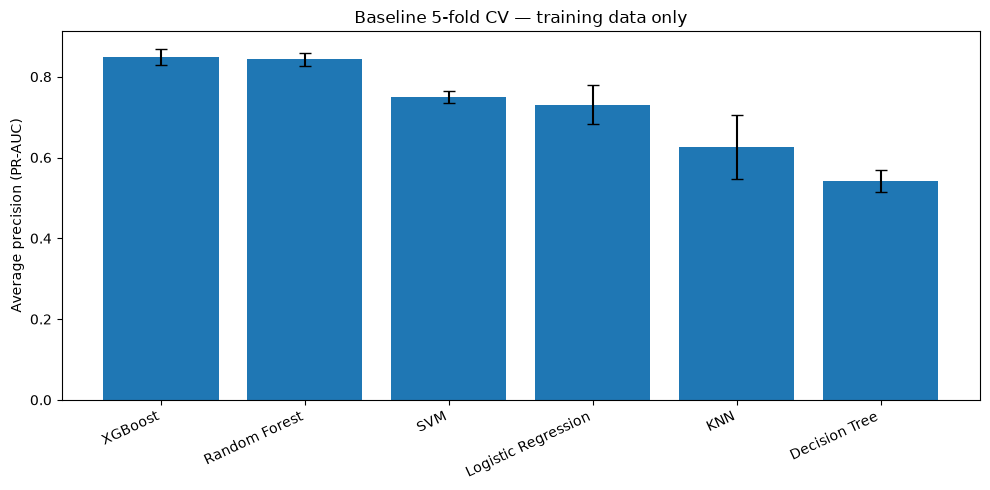

In [7]:
baseline_rows = []
for name, estimator in models.items():
    X_fit, y_fit = model_data[name]
    result = cross_validate(
        estimator, X_fit, y_fit, cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False, error_score="raise",
    )
    row = {"model": name}
    for metric in scoring:
        values = result[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std()
    baseline_rows.append(row)

baseline_results = pd.DataFrame(baseline_rows).sort_values(
    "average_precision_mean", ascending=False
).reset_index(drop=True)
display(baseline_results.style.format({
    col: "{:.4f}" for col in baseline_results.columns if col != "model"
}))

plt.figure(figsize=(10, 5))
plt.bar(
    baseline_results["model"], baseline_results["average_precision_mean"],
    yerr=baseline_results["average_precision_std"], capsize=4,
)
plt.ylabel("Average precision (PR-AUC)")
plt.title("Baseline 5-fold CV — training data only")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 7. Randomized hyperparameter search

**What:** Search model settings with `RandomizedSearchCV`, optimizing
`average_precision` using 5-fold CV. All transforms and KNN undersampling stay
inside each candidate's pipeline and are fitted only on its training fold.
The search uses a bounded number of draws to make a first full run more
practical; increase `N_ITER` for a more exhaustive search.

**Why randomized rather than exhaustive grid search?** It explores broad
continuous and discrete ranges with fewer fits. Search runs only on the
training partition (and the prescribed small subset for KNN/SVM). Results are
not final unbiased performance estimates; nested CV below estimates that.

### Hyperparameters in plain English

- **LR `C`:** inverse regularization strength; smaller values constrain
  coefficients more. **Penalty:** `l1` can zero coefficients, while `l2`
  shrinks them smoothly. `liblinear` and `saga` support the tested combinations.
- **Decision tree `max_depth`:** maximum tree depth; `None` allows full growth.
  **`min_samples_leaf`:** minimum observations in a leaf; **`min_samples_split`:**
  minimum observations needed to split a node. **`criterion`:** impurity measure
  (`gini` or `entropy`).
- **Random forest `n_estimators`:** number of trees. **`max_depth`:** depth per
  tree. **`max_features`:** features considered at each split. **`min_samples_leaf`:**
  minimum rows per leaf; larger values regularize.
- **KNN `n_neighbors`:** number of nearby training points. **`weights`:** equal
  vote (`uniform`) or closer neighbors vote more (`distance`). **`p`:** distance
  power; `p=1` is Manhattan distance and `p=2` Euclidean distance.
- **SVM `C`:** penalty for margin violations. **`kernel`:** linear boundary or
  nonlinear radial-basis (`rbf`) boundary. **`gamma`:** RBF influence radius;
  larger gamma gives more localized influence. `scale` derives a value from
  training-fold features.
- **XGBoost `n_estimators`:** boosting rounds. **`learning_rate`:** contribution
  of each tree. **`max_depth`:** tree complexity. **`min_child_weight`:**
  minimum Hessian mass in a child. **`subsample`:** row fraction per tree.
  **`colsample_bytree`:** feature fraction per tree. **`gamma`:** minimum loss
  reduction for a split. **`reg_alpha` / `reg_lambda`:** L1/L2 regularization.
  **`scale_pos_weight`:** positive-class loss weight, centered around the
  training negative/positive ratio to account for rarity.

In [ ]:
N_ITER = 4  # Increase for broader exploration; every draw is evaluated in 5 folds.

search_spaces = {
    "Logistic Regression": [
        {
            "model__C": loguniform(1e-3, 1e2),
            "model__penalty": ["l1", "l2"],
            "model__solver": ["liblinear"],
        },
        {
            "model__C": loguniform(1e-3, 1e2),
            "model__penalty": ["l1", "l2"],
            "model__solver": ["saga"],
        },
    ],
    "Decision Tree": {
        "model__max_depth": [None, 4, 8, 16, 24],
        "model__min_samples_leaf": randint(1, 20),
        "model__min_samples_split": randint(2, 30),
        "model__criterion": ["gini", "entropy"],
    },
    "Random Forest": {
        "model__n_estimators": randint(100, 301),
        "model__max_depth": [None, 8, 16, 24],
        "model__max_features": ["sqrt", "log2", 0.5],
        "model__min_samples_leaf": randint(1, 10),
    },
    "KNN": {
        "model__n_neighbors": randint(3, 32),
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    },
    "SVM": {
        "model__C": loguniform(1e-2, 1e2),
        "model__kernel": ["linear", "rbf"],
        "model__gamma": ["scale", "auto"],
    },
}

if HAS_XGBOOST:
    search_spaces["XGBoost"] = {
        "model__n_estimators": randint(100, 301),
        "model__learning_rate": loguniform(0.02, 0.3),
        "model__max_depth": randint(2, 9),
        "model__min_child_weight": loguniform(0.5, 10),
        "model__subsample": uniform(0.65, 0.35),
        "model__colsample_bytree": uniform(0.65, 0.35),
        "model__gamma": uniform(0, 2),
        "model__reg_alpha": loguniform(1e-4, 10),
        "model__reg_lambda": loguniform(1e-2, 20),
        "model__scale_pos_weight": loguniform(max(1, xgb_ratio / 3), xgb_ratio * 3),
    }


def make_search(name, estimator, n_iter=N_ITER):
    return RandomizedSearchCV(
        estimator=estimator,
        param_distributions=search_spaces[name],
        n_iter=n_iter,
        scoring="average_precision",
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        verbose=1,
        error_score="raise",
    )


searches = {}
for name, estimator in models.items():
    X_fit, y_fit = model_data[name]
    search = make_search(name, estimator)
    search.fit(X_fit, y_fit)
    searches[name] = search
    print(f"\n{name}: best CV PR-AUC={search.best_score_:.5f}")
    print("Best params:", search.best_params_)

Fitting 5 folds for each of 4 candidates, totalling 20 fits


C:\Users\admin\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\admin\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(



Logistic Regression: best CV PR-AUC=0.73037
Best params: {'model__C': np.float64(9.6098129470364), 'model__penalty': 'l1', 'model__solver': 'liblinear'}
Fitting 5 folds for each of 4 candidates, totalling 20 fits


## 8. Nested cross-validation

**What:** The outer 5-fold loop holds out one training fold at a time; each
outer training portion runs an inner randomized search, and the selected
candidate is scored on the untouched outer fold. The outer shuffle uses seed
123, intentionally different from the baseline/inner folds. **Why nested CV?**
Reporting the same CV score used to select hyperparameters is optimistically
biased. In nested CV, each outer score comes from data not used by that fold's
search. It is still an estimate, not a guarantee of future performance.

This is computationally expensive (models × outer folds × inner folds × draws).
To keep the notebook bounded, the nested search uses 2 randomized draws per
outer fold while retaining the same search spaces and scoring criterion. SVM
and KNN outer CV use the training-only subsample described above.

In [ ]:
OUTER_SEARCH_ITER = 2
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
nested_rows = []

for name, estimator in models.items():
    X_fit, y_fit = model_data[name]
    fold_scores = []
    for fold_number, (train_idx, valid_idx) in enumerate(outer_cv.split(X_fit, y_fit), start=1):
        inner_search = make_search(name, estimator, n_iter=OUTER_SEARCH_ITER)
        inner_search.fit(X_fit.iloc[train_idx], y_fit.iloc[train_idx])
        outer_score = average_precision_score(
            y_fit.iloc[valid_idx],
            inner_search.best_estimator_.fit(
                X_fit.iloc[train_idx], y_fit.iloc[train_idx]
            ).predict_proba(X_fit.iloc[valid_idx])[:, 1]
            if hasattr(inner_search.best_estimator_.named_steps["model"], "predict_proba")
            else inner_search.best_estimator_.decision_function(X_fit.iloc[valid_idx]),
        )
        fold_scores.append(outer_score)
        print(f"{name}: outer fold {fold_number}/5 PR-AUC={outer_score:.5f}")
    nested_rows.append({
        "model": name,
        "nested_pr_auc_mean": float(np.mean(fold_scores)),
        "nested_pr_auc_std": float(np.std(fold_scores)),
    })

nested_results = pd.DataFrame(nested_rows)
comparison = baseline_results[["model", "average_precision_mean", "average_precision_std"]].merge(
    nested_results, on="model", how="inner"
).sort_values("nested_pr_auc_mean", ascending=False)
display(comparison.style.format({
    col: "{:.4f}" for col in comparison.columns if col != "model"
}))

## 9. Training-only threshold tuning

**What:** Select the candidate with the highest nested-CV mean PR-AUC, then
generate out-of-fold (OOF) training scores and plot its precision-recall curve.
Choose (a) the threshold maximizing F1 and (b) the threshold minimizing
`₹10,000 × false negatives + ₹50 × false positives`.

**Why not use the default 0.5 threshold?** It is arbitrary and can be poor for
rare-event detection. **Why OOF scores?** Each training row is scored by a model
that did not fit on that row. For SVM, the ranking model itself uses
`decision_function`; threshold tuning wraps it in sigmoid calibration fitted
within CV, because raw margins are not probabilities. The monetary cost from
probabilities is illustrative and depends on calibrated scores, actual loss,
and operational capacity. We choose the business-cost threshold for the final
holdout report before opening the holdout.

In [ ]:
best_name = comparison.iloc[0]["model"]
best_pipeline = searches[best_name].best_estimator_
X_best, y_best = model_data[best_name]
threshold_model = best_pipeline

if best_name == "SVM":
    # Calibration uses only folds of the training subset; SVC remains probability=False.
    try:
        threshold_model = CalibratedClassifierCV(
            estimator=clone(best_pipeline), method="sigmoid", cv=3, n_jobs=-1
        )
    except TypeError:  # compatibility with older scikit-learn
        threshold_model = CalibratedClassifierCV(
            base_estimator=clone(best_pipeline), method="sigmoid", cv=3
        )
    oof_scores = cross_val_predict(
        threshold_model, X_best, y_best,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        method="predict_proba", n_jobs=1,
    )[:, 1]
    threshold_scores_are_probabilities = True
elif hasattr(best_pipeline.named_steps["model"], "predict_proba"):
    oof_scores = cross_val_predict(
        best_pipeline, X_best, y_best,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        method="predict_proba", n_jobs=1,
    )[:, 1]
    threshold_scores_are_probabilities = True
else:
    oof_scores = cross_val_predict(
        best_pipeline, X_best, y_best,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        method="decision_function", n_jobs=1,
    )
    threshold_scores_are_probabilities = False

precision, recall, thresholds = precision_recall_curve(y_best, oof_scores)
f1_values = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
f1_threshold = float(thresholds[int(np.nanargmax(f1_values))])

if not threshold_scores_are_probabilities:
    raise RuntimeError(
        "Business-cost thresholds require calibrated probabilities. "
        "The selected non-probabilistic estimator must be calibrated before proceeding."
    )

costs = []
for threshold in thresholds:
    predictions = (oof_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_best, predictions, labels=[0, 1]).ravel()
    costs.append(10_000 * fn + 50 * fp)
cost_threshold = float(thresholds[int(np.argmin(costs))])

print(f"Selected model by nested CV: {best_name}")
print(f"OOF threshold maximizing F1: {f1_threshold:.6f}")
print(f"OOF threshold minimizing illustrative business cost: {cost_threshold:.6f}")
print(f"Minimum OOF cost: ₹{min(costs):,.0f}")
PrecisionRecallDisplay.from_predictions(y_best, oof_scores)
plt.title(f"Training-only OOF precision-recall curve — {best_name}")
plt.show()

## 10. Final holdout evaluation — the only test-set evaluation

**What:** Refit the selected, tuned pipeline on all training data eligible for
that model workflow; then score the untouched holdout exactly once. KNN/SVM
remain on the declared training-only subsample for feasibility if selected.
Report average precision, ROC-AUC, precision, recall, F1, and a confusion
matrix at the preselected business-cost threshold. Also show the
training-selected max-F1 threshold for context.

**Why report both thresholds?** A low threshold often raises recall but creates
more false alarms. The business threshold is selected from training OOF data;
the F1 threshold is also selected without holdout labels. Do not adjust either
threshold after seeing holdout results.

In [ ]:
# This is the first cell that inspects holdout labels or computes metrics.
if y_test.nunique() != 2:
    raise ValueError("The final holdout must contain both classes to compute ROC-AUC.")
X_test_model = X_test_raw.drop(columns=id_columns, errors="ignore")
final_model = clone(threshold_model)
final_model.fit(X_best, y_best)

if hasattr(final_model, "predict_proba"):
    test_scores = final_model.predict_proba(X_test_model)[:, 1]
else:
    test_scores = final_model.decision_function(X_test_model)

if threshold_scores_are_probabilities:
    test_pr_auc = average_precision_score(y_test, test_scores)
    test_roc_auc = roc_auc_score(y_test, test_scores)
    report_rows = []
    for label, threshold in [
        ("Business-cost threshold", cost_threshold),
        ("Max-F1 threshold", f1_threshold),
    ]:
        test_predictions = (test_scores >= threshold).astype(int)
        report_rows.append({
            "threshold_choice": label,
            "threshold": threshold,
            "precision": precision_score(y_test, test_predictions, zero_division=0),
            "recall": recall_score(y_test, test_predictions, zero_division=0),
            "f1": f1_score(y_test, test_predictions, zero_division=0),
        })
    test_report = pd.DataFrame(report_rows)
    print(f"Final model: {best_name}")
    print(f"Holdout PR-AUC (average precision): {test_pr_auc:.5f}")
    print(f"Holdout ROC-AUC: {test_roc_auc:.5f}")
    display(test_report)
    business_predictions = (test_scores >= cost_threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, business_predictions, display_labels=["Genuine", "Fraud"],
        values_format="d", cmap="Blues",
    )
    plt.title("Holdout confusion matrix — business-cost threshold")
    plt.show()
    PrecisionRecallDisplay.from_predictions(y_test, test_scores)
    plt.title("Holdout precision-recall curve (final evaluation)")
    plt.show()
    RocCurveDisplay.from_predictions(y_test, test_scores)
    plt.title("Holdout ROC curve (secondary metric)")
    plt.show()
else:
    raise RuntimeError("Final selected model must provide calibrated probability scores.")

## 11. Model interpretation

**What:** Show transformed-feature coefficients for logistic regression or
feature importances for tree-based models. **Why:** These provide a useful
diagnostic view of which encoded columns influence the fitted model.
**Why not call them causal effects?** Correlated predictors, sampling,
regularization, and model structure affect importance; importance does not
establish that a feature causes fraud. SVM/KNN do not provide comparable native
feature importances, so report that limitation rather than inventing one.

In [ ]:
fitted_pipeline = final_model
core_pipeline = fitted_pipeline.calibrated_classifiers_[0].estimator if best_name == "SVM" else fitted_pipeline
if isinstance(core_pipeline, Pipeline):
    fitted_preprocessor = core_pipeline.named_steps["preprocess"]
    fitted_estimator = core_pipeline.named_steps["model"]
    try:
        feature_names = fitted_preprocessor.get_feature_names_out()
    except (AttributeError, ValueError):
        feature_names = np.asarray([f"feature_{i}" for i in range(
            fitted_preprocessor.transform(X_best.iloc[:1]).shape[1]
        )])

    if hasattr(fitted_estimator, "feature_importances_"):
        importances = fitted_estimator.feature_importances_
        importance_title = "Tree-based feature importance"
        values = importances
    elif hasattr(fitted_estimator, "coef_"):
        values = np.abs(np.ravel(fitted_estimator.coef_))
        importance_title = "Absolute logistic-regression coefficients"
    else:
        values = None

    if values is not None:
        importance = pd.Series(values, index=feature_names).sort_values(ascending=False).head(20)
        display(importance.rename("importance").to_frame())
        importance.sort_values().plot(kind="barh", figsize=(9, 7), title=importance_title)
        plt.tight_layout()
        plt.show()
    else:
        print(f"{best_name} has no directly comparable native feature importance.")
else:
    print(f"{best_name} is calibrated; inspect its underlying estimator for model-specific interpretation.")

## 12. Save the deployable artifact

**What:** Persist the fitted preprocessing/model pipeline and the threshold
selected from training-only OOF predictions in a single joblib bundle.
**Why:** Saving only the classifier would omit imputation, scaling, encoding,
feature engineering, and the operating threshold. **Why not save test outputs
as the model?** Predictions are evaluation evidence, not part of the estimator.
For deployment, monitor calibration, drift, alert volume, and fraud capture;
the illustrative business costs should be replaced with agreed operational
costs.

In [ ]:
artifact_path = Path("credit-card-fraud-model.joblib")
artifact = {
    "pipeline": final_model,
    "threshold": cost_threshold,
    "threshold_name": "minimum_training_oof_business_cost",
    "model_name": best_name,
    "feature_columns": list(X_best.columns),
    "random_state": RANDOM_STATE,
    "metrics": {
        "holdout_average_precision": float(test_pr_auc),
        "holdout_roc_auc": float(test_roc_auc),
    },
}
joblib.dump(artifact, artifact_path)
print(f"Saved pipeline and decision threshold to {artifact_path.resolve()}")

## Model Evaluation Report

Fill this report from the tables printed above; do not compare or tune models
using holdout results. The primary metric is holdout average precision. Recall
and precision at the selected threshold describe the operational trade-off.

### Five-line interview summary

1. **Problem:** Detect rare fraudulent credit-card transactions while balancing missed fraud against false alarms.
2. **Data:** An anonymized, highly imbalanced transaction dataset with `Time`, PCA features, `Amount`, and binary `Class`.
3. **Approach:** Chronological holdout, fold-fitted preprocessing, class-aware pipelines, PR-AUC cross-validation, nested tuning, and training-only threshold selection.
4. **Best model + metrics:** Use the reported nested-CV-selected model; quote its final holdout PR-AUC, ROC-AUC, precision, recall, and F1 at the chosen threshold.
5. **Next steps:** Validate on later production data, calibrate against real costs, monitor drift and alert capacity, and revisit thresholds with stakeholders.